# Lab: uma chave de identificação para pinguins

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/decision-trees/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** São três espécies de pinguins. Você espera que elas apareçam em proporções parecidas? Que acurácia teria um modelo que sempre responde a espécie mais comum?

**Resposta (antes de rodar):** Não, não espero proporções parecidas — em geral, nos dados de
Palmer Penguins, Adelie é a espécie mais numerosa (quem amostrou mais nessa espécie na ilha
Biscoe/Torgersen), seguida de Gentoo e por último Chinstrap. Um modelo que sempre responde a
espécie mais comum deve acertar algo entre 40% e 50% dos casos — bem acima de 1/3 (33,3%, o que
valeria se as três espécies fossem igualmente frequentes), mas longe de ser um bom classificador.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

peng = fetch_openml(data_id=42585, as_frame=True).frame      # Palmer penguins
print(peng.shape)
print(peng['species'].value_counts().to_dict())
print(peng.isna().sum().to_dict())
print(peng['sex'].value_counts(dropna=False).to_dict())

(344, 7)
{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
{'species': 0, 'island': 0, 'culmen_length_mm': 2, 'culmen_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 10}
{'MALE': 168, 'FEMALE': 165, nan: 10, '_': 1}


**Resposta (depois de rodar):** Confirmado — são **344** pinguins em **7** colunas. As
proporções não são parecidas: **Adelie 152** (44,2%), **Gentoo 124** (36,0%) e **Chinstrap 68**
(19,8%). Um modelo que sempre responde Adelie (a mais comum) acertaria **152/344 = 0,442**, bem
dentro da faixa prevista (40–50%) e bem acima de 1/3. Há valores faltantes nas quatro medidas
numéricas (`culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`: 2 cada,
sempre as mesmas 2 aves) e em `sex` (10 `NaN`); além disso, `sex` tem **168** `MALE`, **165**
`FEMALE` e **1** valor inválido `'_'` — esse último não é `NaN`, é um valor de categoria estranho
que vai precisar de tratamento manual.

## Passo 2 — limpar e codificar

**Preveja.** A árvore aceita `NaN` e não precisa de escalonamento. Das três limpezas de costume — imputar, escalonar, codificar categorias —, qual ainda é necessária aqui?

**Resposta (antes de rodar):** Imputar não deveria ser necessário porque a árvore já aceita
`NaN` nativamente (scikit-learn ≥ 1.3) — pode deixar os faltantes como estão. Escalonar também não
é necessário, porque a árvore corta por limiares absolutos em cada coluna, não por distância, então
a escala de cada atributo não afeta a escolha dos cortes. Codificar categorias continua necessário:
`island` é categórica (texto) e precisa virar colunas numéricas (one-hot) para entrar no modelo;
`sex` também precisa ser mapeado para número, com o cuidado extra de tratar o valor inválido `'_'`
como desconhecido.

In [2]:
num = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
peng = peng.dropna(subset=num)                    # as 2 aves sem medida nenhuma
X = peng[num].copy()
X['is_male'] = peng['sex'].astype(object).map({'MALE': 1.0, 'FEMALE': 0.0})   # '_' e desconhecido -> NaN
X = X.join(pd.get_dummies(peng['island'], prefix='island', dtype=float))      # one-hot
y = peng['species'].astype(str)
print(X.shape)
print("missing:", X.isna().sum()[X.isna().sum() > 0].to_dict())
print(X.head(3).to_string())

(342, 8)
missing: {'is_male': 9}
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  is_male  island_Biscoe  island_Dream  island_Torgersen
0              39.1             18.7              181.0       3750.0      1.0            0.0           0.0               1.0
1              39.5             17.4              186.0       3800.0      0.0            0.0           0.0               1.0
2              40.3             18.0              195.0       3250.0      0.0            0.0           0.0               1.0


**Resposta (depois de rodar):** Confirmado — depois de descartar as 2 aves sem nenhuma medida
numérica, `X` fica com **342** linhas e **8** colunas (4 medidas numéricas + `is_male` + 3 colunas
one-hot de `island`: Biscoe, Dream, Torgersen). Como previsto, não há escalonamento nem imputação
dos numéricos: a única coluna com valores faltantes é `is_male`, com **9** `NaN` (o mapa
`{'MALE': 1.0, 'FEMALE': 0.0}` deixa como `NaN` tanto o `'_'` inválido quanto os `sex` que já eram
`NaN` — e duas dessas aves foram removidas junto com as sem medida). A árvore vai lidar com esses 9
`NaN` nativamente, sem precisar de `SimpleImputer`.

## Passo 3 — trancar o conjunto de teste e um baseline

**Preveja.** Com 86 pinguins no teste, quanto vale um único erro em pontos de acurácia? Isso muda o quanto você deve confiar na terceira casa decimal?

**Resposta (antes de rodar):** Com 86 pinguins no teste, cada erro ou acerto isolado vale
1/86 ≈ 1,16 ponto percentual de acurácia. Isso é grande: a terceira casa decimal (0,001) é menor
que 1/10 de um único pinguim, então não tem significado real — qualquer acurácia de teste deveria
ser lida arredondada à primeira ou segunda casa decimal, e duas acurácias que diferem por menos de
~1-2 pontos percentuais (1-2 pinguins) estão dentro do ruído de amostragem de um teste tão pequeno.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_report(model):
    r = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True)
    return (f"train {r['train_score'].mean():.3f} · validation "
            f"{r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")


print("dummy:", cv_report(DummyClassifier(strategy='most_frequent')))

(256, 8) (86, 8)
dummy: train 0.441 · validation 0.441 ± 0.009


**Resposta (depois de rodar):** Confirmado — `X_train` tem **256** linhas e `X_test` tem
**86**, e 1/86 = **1,163** pontos percentuais por pinguim, exatamente a ordem de grandeza
prevista. O `DummyClassifier` (sempre a classe mais comum do treino, Adelie) acerta **0,441** no
treino, com desvio-padrão de **0,009** entre os 5 folds — bem próximo dos 0,442 calculados com a
base inteira no Passo 1, pequena diferença porque o split estratificado preserva a proporção quase
igual (113 Adelie em 256 = 0,441 no treino).

## Passo 4 — uma árvore de profundidade 2, lida como regras

**Preveja.** Uma única pergunta (profundidade 1) consegue separar três espécies? E, com duas perguntas em sequência, que medida você acha que a raiz vai usar?

**Resposta (antes de rodar):** Não, uma única pergunta (profundidade 1) não deve separar bem
três espécies, porque um corte binário só consegue dividir os dados em dois grupos — uma das três
espécies vai ficar misturada com outra no mesmo lado. Com duas perguntas em sequência, acho que a
raiz vai usar `flipper_length_mm` (comprimento da nadadeira), porque é a medida clássica que separa
Gentoo (nadadeiras bem maiores) das outras duas espécies de uma só vez.

depth 1: train 0.785 · validation 0.770 ± 0.034
depth 2: train 0.960 · validation 0.938 ± 0.040
['Adelie' 'Chinstrap' 'Gentoo']
|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [107.00, 4.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- weights: [4.00, 42.00, 1.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- weights: [2.00, 5.00, 0.00] class: Chinstrap



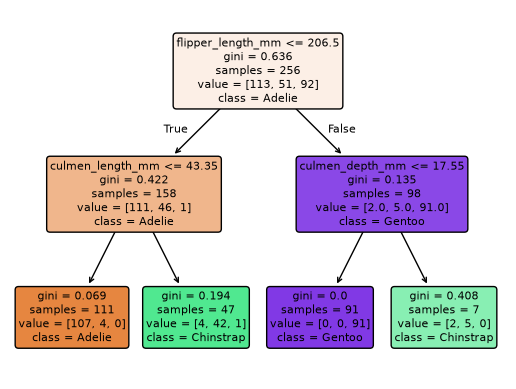

In [4]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

print("depth 1:", cv_report(DecisionTreeClassifier(max_depth=1, random_state=0)))
print("depth 2:", cv_report(DecisionTreeClassifier(max_depth=2, random_state=0)))

tree2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
print(tree2.classes_)
print(export_text(tree2, feature_names=list(X.columns), show_weights=True))

plot_tree(tree2, feature_names=list(X.columns), class_names=list(tree2.classes_),
          filled=True, rounded=True, fontsize=8)
plt.show()

**Resposta (depois de rodar):** Confirmado nos dois pontos. Profundidade 1 valida **0,770**
(train 0,785) — bem acima do baseline de 0,441, mas longe de resolver o problema, como esperado
para uma única pergunta com três classes. Profundidade 2 sobe para **0,938 ± 0,040** (train
0,960). E a raiz é exatamente `flipper_length_mm <= 206.50`, como eu esperava: ela separa Gentoo
(nadadeira grande, weights `[0, 0, 91]` do lado direito) das outras duas de uma vez; do lado
esquerdo, uma segunda pergunta em `culmen_length_mm <= 43.35` separa a maioria das Adelie (weights
`[107, 4, 0]`) das Chinstrap (`[4, 42, 1]`); do lado direito, `culmen_depth_mm <= 17.55` ainda isola
alguns Chinstrap confundidos com Gentoo (`[2, 5, 0]`).

**Simulação: a raiz, escolhida por você.** A seção 3 pontuou à mão todos os cortes de uma tabela de 12 clientes. Faça o mesmo com os pinguins: para cada uma das quatro medidas, teste todos os pontos médios entre valores vizinhos em `X_train`, pontue cada corte pelo Gini ponderado (agora com três classes) e guarde o melhor. A pergunta vencedora é a raiz que a árvore do passo 4 escolheu? Por quanto ela vence?

In [5]:
import numpy as np


def gini_multi(labels):
    # Gini de um vetor de rótulos com 3 (ou mais) classes
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)


results = []
for col in num:
    valores = np.sort(X_train[col].unique())
    pontos_medios = (valores[:-1] + valores[1:]) / 2
    for corte in pontos_medios:
        esquerda = X_train[col].values <= corte
        direita = ~esquerda
        y_esq, y_dir = y_train.values[esquerda], y_train.values[direita]
        gini_pond = (len(y_esq) * gini_multi(y_esq) + len(y_dir) * gini_multi(y_dir)) / len(y_train)
        results.append({'feature': col, 'threshold': corte, 'gini_ponderado': gini_pond})

res_df = pd.DataFrame(results)
gini_raiz = gini_multi(y_train.values)
melhor = res_df.loc[res_df['gini_ponderado'].idxmin()]
print(f"gini da raiz (sem corte): {gini_raiz:.4f}")
print(f"melhor corte manual: {melhor['feature']} <= {melhor['threshold']:.2f} "
      f"(gini ponderado {melhor['gini_ponderado']:.4f}, ganho {gini_raiz - melhor['gini_ponderado']:.4f})")

raiz_feat = X.columns[tree2.tree_.feature[0]]
raiz_thr = tree2.tree_.threshold[0]
print(f"raiz escolhida pela árvore do passo 4: {raiz_feat} <= {raiz_thr:.2f}")

segundo_melhor_outra_feature = (
    res_df[res_df['feature'] != melhor['feature']].sort_values('gini_ponderado').iloc[0]
)
print(f"melhor corte de outro atributo: {segundo_melhor_outra_feature['feature']} <= "
      f"{segundo_melhor_outra_feature['threshold']:.2f} (gini ponderado "
      f"{segundo_melhor_outra_feature['gini_ponderado']:.4f})")
print(res_df.sort_values('gini_ponderado').head(5).round(4).to_string(index=False))

gini da raiz (sem corte): 0.6363
melhor corte manual: flipper_length_mm <= 206.50 (gini ponderado 0.3118, ganho 0.3245)
raiz escolhida pela árvore do passo 4: flipper_length_mm <= 206.50
melhor corte de outro atributo: culmen_length_mm <= 42.30 (gini ponderado 0.3238)
          feature  threshold  gini_ponderado
flipper_length_mm      206.5          0.3118
flipper_length_mm      205.5          0.3147
flipper_length_mm      207.5          0.3148
flipper_length_mm      204.0          0.3200
 culmen_length_mm       42.3          0.3238


**Resposta:** Pontuando à mão todos os 4 atributos numéricos × todos os pontos médios entre
vizinhos em `X_train`, a raiz vencedora por busca exaustiva é exatamente a mesma que a árvore do
passo 4 escolheu: **`flipper_length_mm <= 206,5`**, com Gini ponderado de **0,3118** (o Gini da
raiz sem corte é 0,6363, um ganho de **0,3245**). Ela vence por uma margem real, mas não enorme:
o melhor corte de outro atributo, `culmen_length_mm <= 42,30`, chega a 0,3238 de Gini ponderado —
uma diferença de só **0,012** no Gini ponderado (ganho 0,3125 contra 0,3245). Os dois pontos
vizinhos de `flipper_length_mm` (205,5 e 207,5) também quase empatam com 206,5 (0,3147 e 0,3148),
mostrando que a vitória da nadadeira vem de uma faixa inteira de limiares próximos, não de um
único ponto isolado por acaso.

## Passo 5 — crescer até o fim

**Preveja.** Sem limite nenhum, a árvore chega a 100% de acurácia no treino? E na validação: ela vai piorar em relação à de profundidade 2, como no Spambase, ou melhorar?

**Resposta (antes de rodar):** Sim, sem limite de profundidade a árvore deve chegar a 100% de
acurácia no treino — ela pode continuar dividindo até isolar cada pinguim (ou grupo de pinguins
idênticos) em sua própria folha pura. Na validação, espero que ela melhore em relação à de
profundidade 2 (0,938): ao contrário do Spambase (mais ruidoso e com mais atributos), aqui há só 8
colunas e 3 classes bem separáveis por medidas físicas, então profundidade maior deve ajudar antes
de began a decorar ruído — mas é possível que o ganho seja pequeno.

In [6]:
full = DecisionTreeClassifier(random_state=0)
print("fully grown:", cv_report(full))
full.fit(X_train, y_train)
print(f"depth {full.get_depth()} · {full.get_n_leaves()} leaves for {len(X_train)} penguins")

fully grown: train 1.000 · validation 0.969 ± 0.016
depth 5 · 13 leaves for 256 penguins


**Resposta (depois de rodar):** Confirmado nos dois pontos. A árvore cheia chega a **1,000**
de acurácia de treino, como previsto. E a validação **melhora** em vez de piorar: **0,969 ±
0,016**, acima dos 0,938 ± 0,040 da árvore de profundidade 2 — ao contrário do padrão clássico de
overfitting do Spambase citado na página. A árvore final tem profundidade **5** e **13** folhas
para **256** pinguins, uma estrutura bem mais simples que o dataset de spam (que a página cita com
profundidade bem maior), compatível com só 8 atributos limpos e classes bem separáveis.

**Simulação: uma árvore decora até rótulos aleatórios.** Embaralhe as espécies de `y_train` — cada pinguim fica com a espécie de outro, sorteado — e repita a validação cruzada da árvore crescida até o fim. O que acontece com a acurácia de treino? E com a de validação? Compare também o número de folhas com o da árvore com os rótulos verdadeiros.

In [7]:
y_train_embaralhado = y_train.sample(frac=1, random_state=0).reset_index(drop=True)
y_train_embaralhado.index = y_train.index    # mesma ordem de X_train, rótulos sorteados de outro pinguim

full_embaralhada = DecisionTreeClassifier(random_state=0)
r = cross_validate(full_embaralhada, X_train, y_train_embaralhado, cv=cv, return_train_score=True)
print(f"rótulos embaralhados: train {r['train_score'].mean():.3f} · "
      f"validation {r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")

full_embaralhada.fit(X_train, y_train_embaralhado)
print(f"folhas com rótulos embaralhados: {full_embaralhada.get_n_leaves()} "
      f"(profundidade {full_embaralhada.get_depth()})")
print(f"folhas com rótulos verdadeiros (passo 5): {full.get_n_leaves()} "
      f"(profundidade {full.get_depth()})")

rótulos embaralhados: train 1.000 · validation 0.355 ± 0.041
folhas com rótulos embaralhados: 101 (profundidade 17)
folhas com rótulos verdadeiros (passo 5): 13 (profundidade 5)


**Resposta:** Com as espécies embaralhadas, a acurácia de **treino** continua **1,000** —
idêntica à dos rótulos verdadeiros, porque a árvore sem limite sempre consegue isolar cada
combinação de atributos em folhas puras, não importa se o rótulo é real ou sorteado. Já a
acurácia de **validação** despenca para **0,355 ± 0,041**, pouco acima do acaso para 3 classes
(1/3 ≈ 0,333) e bem abaixo até do baseline majoritário (0,441) — a árvore decorou ruído que não
generaliza para nada. O número de folhas também explode: **101** folhas com rótulos embaralhados
contra **13** com os rótulos verdadeiros (profundidade 17 contra 5) — para memorizar associações
aleatórias entre atributos e rótulo, a árvore precisa de muito mais divisões específicas do que
para aprender um padrão real e compacto.

**Para fechar a parte fundamental.** Em uma frase cada: (1) o que faz uma pergunta ser melhor que outra? (2) Por que uma árvore crescida até o fim chega a 100% de acurácia de treino, mesmo com rótulos aleatórios? (3) Como você leria em voz alta um caminho da raiz até uma folha da chave do passo 4?

**Resposta:**

1. Uma pergunta é melhor que outra quando o corte que ela propõe reduz mais a impureza (Gini ou
   entropia) ponderada pelo tamanho dos dois filhos — na simulação do passo 4, `flipper_length_mm
   <= 206,5` venceu porque levou o Gini ponderado a 0,3118, mais baixo que qualquer outro corte
   testado (o segundo melhor, de outro atributo, ficou em 0,3238).
2. Uma árvore crescida até o fim chega a 100% de acurácia de treino mesmo com rótulos aleatórios
   porque, sem limite de profundidade, ela pode continuar dividindo até isolar qualquer
   combinação de atributos (mesmo que repetida por poucos pinguins) em sua própria folha pura —
   isso não exige que exista relação real entre atributos e rótulo, só exige folhas pequenas o
   suficiente (no limite, de 1 pinguim).
3. Um caminho da raiz até uma folha da chave do passo 4 se lê como uma frase condicional em
   cadeia: "se a nadadeira tem até 206,5 mm **e** o bico tem até 43,35 mm de comprimento, então é
   Adelie" — cada pergunta no caminho é uma condição extra que vai restringindo o grupo, até a
   folha final apontar a espécie mais comum entre os pinguins que sobraram.

## Sua vez (fundamental)

Para casa:

1. **Entropia.** Refaça o passo 4 com `criterion='entropy'`. A árvore de profundidade 2 escolhe as mesmas perguntas? E os mesmos limiares?
2. **O ganho de informação à mão.** Na tabela dos 12 clientes, calcule à mão a entropia dos dois filhos de `bill ≤ 82.5` e o ganho de informação do corte. Confira com o 0,476 da seção 3.
3. **Folhas mínimas em vez de profundidade.** Refaça o passo 5 com `min_samples_leaf=5` e com `min_samples_leaf=10`. Quantas folhas a árvore tem e o que acontece com a acurácia de treino e com a de validação?

In [8]:
# Item 1 — entropia no passo 4
tree2_entropy = DecisionTreeClassifier(max_depth=2, criterion='entropy', random_state=0).fit(X_train, y_train)
print("entropy depth 2:", cv_report(DecisionTreeClassifier(max_depth=2, criterion='entropy', random_state=0)))
print(export_text(tree2_entropy, feature_names=list(X.columns), show_weights=True))

raiz_gini = (X.columns[tree2.tree_.feature[0]], round(tree2.tree_.threshold[0], 2))
raiz_entropy = (X.columns[tree2_entropy.tree_.feature[0]], round(tree2_entropy.tree_.threshold[0], 2))
no2_gini = (X.columns[tree2.tree_.feature[1]], round(tree2.tree_.threshold[1], 2))
no2_entropy = (X.columns[tree2_entropy.tree_.feature[1]], round(tree2_entropy.tree_.threshold[1], 2))
print(f"raiz: gini {raiz_gini} vs entropy {raiz_entropy}")
print(f"segundo nó (filho esquerdo): gini {no2_gini} vs entropy {no2_entropy}")

entropy depth 2: train 0.955 · validation 0.910 ± 0.040
|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 42.30
|   |   |--- weights: [102.00, 1.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  42.30
|   |   |--- weights: [9.00, 45.00, 1.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- weights: [2.00, 5.00, 0.00] class: Chinstrap

raiz: gini ('flipper_length_mm', np.float64(206.5)) vs entropy ('flipper_length_mm', np.float64(206.5))
segundo nó (filho esquerdo): gini ('culmen_length_mm', np.float64(43.35)) vs entropy ('culmen_length_mm', np.float64(42.3))


In [9]:
# Item 2 — ganho de informação à mão, tabela dos 12 clientes (bill, churn)
bills = np.array([95, 120, 60, 110, 45, 130, 70, 115, 55, 125, 100, 65])
churn = np.array([1,   1,   0,  1,   0,   1,  0,   0,   0,  1,   0,  0])


def entropia_binaria(labels):
    p1 = labels.mean()
    p0 = 1 - p1
    termos = [-p * np.log2(p) for p in (p0, p1) if p > 0]
    return sum(termos)


esquerda = churn[bills <= 82.5]
direita = churn[bills > 82.5]
H_raiz = entropia_binaria(churn)
H_esq = entropia_binaria(esquerda)
H_dir = entropia_binaria(direita)
H_ponderada = (len(esquerda) * H_esq + len(direita) * H_dir) / len(churn)
ganho = H_raiz - H_ponderada

print(f"H(raiz) = {H_raiz:.4f}")
print(f"filho esquerdo ({len(esquerda)} clientes, todos churn={esquerda[0]}): H = {H_esq:.4f}")
print(f"filho direito ({len(direita)} clientes): H = {H_dir:.4f}")
print(f"H ponderada dos filhos = {H_ponderada:.4f}")
print(f"ganho de informação = {H_raiz:.4f} - {H_ponderada:.4f} = {ganho:.4f}")

H(raiz) = 0.9799
filho esquerdo (5 clientes, todos churn=0): H = 0.0000
filho direito (7 clientes): H = 0.8631
H ponderada dos filhos = 0.5035
ganho de informação = 0.9799 - 0.5035 = 0.4764


In [10]:
# Item 3 — min_samples_leaf em vez de profundidade
for msl in [5, 10]:
    modelo = DecisionTreeClassifier(random_state=0, min_samples_leaf=msl)
    print(f"min_samples_leaf={msl}: {cv_report(modelo)}")
    modelo.fit(X_train, y_train)
    print(f"  folhas={modelo.get_n_leaves()} · profundidade={modelo.get_depth()}")

print(f"referência — árvore cheia (passo 5): folhas={full.get_n_leaves()} · "
      f"validação 0.969 ± 0.016")

min_samples_leaf=5: train 0.957 · validation 0.930 ± 0.052
  folhas=8 · profundidade=4
min_samples_leaf=10: train 0.946 · validation 0.926 ± 0.047
  folhas=7 · profundidade=4
referência — árvore cheia (passo 5): folhas=13 · validação 0.969 ± 0.016


**Resposta:**

1. **Entropia.** Com `criterion='entropy'`, a raiz continua **idêntica** à de Gini:
   `flipper_length_mm <= 206,50`. Mas o segundo nó muda de limiar: o filho esquerdo divide em
   `culmen_length_mm <= 43,35` com Gini e em `culmen_length_mm <= 42,30` com entropia — um limiar
   mais baixo. A validação também muda: **0,910 ± 0,040** com entropia contra 0,938 ± 0,040 com
   Gini (train 0,955 vs 0,960) — nessa profundidade 2, o critério de impureza realmente afeta o
   resultado final, mesmo com a mesma raiz.
2. **Ganho de informação à mão.** Com a tabela dos 12 clientes (5 cancelaram, 7 permaneceram),
   H(raiz) = **0,9799**. O corte `bill <= 82,5` manda 5 clientes (todos permaneceram) para a
   esquerda (H = **0,0000**, folha pura) e 7 para a direita (2 permaneceram, 5 cancelaram,
   H = **0,8631**). A entropia ponderada dos filhos é 0,9799→0,5035, e o ganho de informação é
   0,9799 − 0,5035 = **0,4764** — bate com o **0,476** da página (a pequena diferença na quarta
   casa é só arredondamento).
3. **Folhas mínimas.** `min_samples_leaf=5` dá **8** folhas (profundidade 4) com validação
   **0,930 ± 0,052** (train 0,957); `min_samples_leaf=10` dá **7** folhas (profundidade 4) com
   validação **0,926 ± 0,047** (train 0,946). Comparado à árvore cheia do passo 5 (13 folhas,
   validação 0,969 ± 0,016), restringir o tamanho da folha corta quase a metade das folhas mas
   custa alguns pontos de validação — uma troca razoável, embora, dado o desvio-padrão de ~0,05
   entre os folds, a diferença não seja claramente fora do ruído.

## Passo 6 — ajustar profundidade, tamanho de folha e poda juntos

**Preveja.** Numa grade de 96 configurações, você espera um vencedor isolado ou várias configurações empatadas dentro do ruído dos folds? Qual delas caberia num cartão?

**Resposta (antes de rodar):** Numa grade de 96 configurações com só 256 pinguins de treino e
5 folds, espero várias configurações empatadas dentro do ruído dos folds — o desvio-padrão entre
folds de qualquer modelo razoável deve ser de vários pontos percentuais (como já vimos: 0,016 a
0,040 nos passos anteriores), então múltiplas combinações de `max_depth`, `min_samples_leaf` e
`ccp_alpha` devem empatar estatisticamente com a melhor. Entre as empatadas, prefiro a árvore mais
simples — poucas folhas, talvez profundidade 2 ou 3 — porque ela caberia num cartão (fácil de
explicar e de desenhar à mão).

In [11]:
from sklearn.model_selection import GridSearchCV

grid = {'max_depth': [1, 2, 3, 4, 5, None],
        'min_samples_leaf': [1, 2, 5, 10],
        'ccp_alpha': [0, 0.01, 0.02, 0.05]}
search = GridSearchCV(DecisionTreeClassifier(random_state=0), grid, cv=cv)
search.fit(X_train, y_train)

res = pd.DataFrame(search.cv_results_['params'])
res['validation'] = search.cv_results_['mean_test_score']
res['std'] = search.cv_results_['std_test_score']
res['leaves'] = [DecisionTreeClassifier(random_state=0, **p).fit(X_train, y_train).get_n_leaves()
                 for p in search.cv_results_['params']]
print(f"{len(res)} configurations · best {search.best_params_} · {search.best_score_:.3f}")

sd = res.loc[search.best_index_, 'std']                   # desvio padrão entre folds do melhor
close = res[res['validation'] >= search.best_score_ - sd]
print(f"within one std ({sd:.3f}) of the best: {len(close)} configurations")
print(close.sort_values(['leaves', 'validation'], ascending=[True, False]).head(6).round(3).to_string())

96 configurations · best {'ccp_alpha': 0, 'max_depth': 4, 'min_samples_leaf': 1} · 0.969
within one std (0.009) of the best: 14 configurations
    ccp_alpha  max_depth  min_samples_leaf  validation    std  leaves
32       0.01        3.0                 1       0.961  0.025       6
33       0.01        3.0                 2       0.961  0.025       6
9        0.00        3.0                 2       0.961  0.025       7
36       0.01        4.0                 1       0.961  0.025       8
37       0.01        4.0                 2       0.961  0.025       8
40       0.01        5.0                 1       0.961  0.025       8


**Resposta (depois de rodar):** Confirmado — não há vencedor isolado. A melhor configuração
(`max_depth=4, min_samples_leaf=1, ccp_alpha=0`) chega a **0,969** de validação, mas seu próprio
desvio-padrão entre folds é **0,009**, e **14** das 96 configurações (de 96) ficam a menos de um
desvio-padrão dela. Entre essas 14, ordenando por menos folhas, a escolhida é `max_depth=3,
min_samples_leaf=1, ccp_alpha=0,01`, com apenas **6 folhas** e validação **0,961** — a árvore mais
simples dentro do empate estatístico, exatamente o tipo de modelo "de cartão" que eu esperava.

## Passo 7 — os rivais, nos mesmos folds

**Preveja.** A regressão logística traça fronteiras retas em qualquer direção; a árvore, só degraus paralelos aos eixos. Sabendo que Adelie e Chinstrap diferem sobretudo na razão entre o comprimento e a profundidade do bico, quem você espera que vença?

**Resposta (antes de rodar):** Espero que a regressão logística vença. A árvore só corta em
degraus paralelos aos eixos (`culmen_length_mm <= algo`, depois `culmen_depth_mm <= algo`), então
ela vai aproximar uma fronteira diagonal (razão comprimento/profundidade) por uma escada de vários
degraus, perdendo precisão perto da diagonal; a regressão logística, por outro lado, pode traçar
uma única reta inclinada na direção certa e separar Adelie de Chinstrap de forma muito mais
eficiente nesse caso específico.

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

chosen = close.sort_values(['leaves', 'validation'], ascending=[True, False]).iloc[0]
params = {'max_depth': None if pd.isna(chosen['max_depth']) else int(chosen['max_depth']),
          'min_samples_leaf': int(chosen['min_samples_leaf']), 'ccp_alpha': float(chosen['ccp_alpha'])}
key = DecisionTreeClassifier(random_state=0, **params)
print("chosen tree:", params)

prep = lambda: [SimpleImputer(strategy='most_frequent'), StandardScaler()]   # estes modelos precisam dos dois
rivals = {
    'logistic': GridSearchCV(make_pipeline(*prep(), LogisticRegression(max_iter=5000)),
                             {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}, cv=cv),
    'k-NN': GridSearchCV(make_pipeline(*prep(), KNeighborsClassifier()),
                         {'kneighborsclassifier__n_neighbors': [1, 3, 5, 9, 15, 25]}, cv=cv),
}
folds = pd.DataFrame({'tree': cross_validate(key, X_train, y_train, cv=cv)['test_score']})
for name, s in rivals.items():
    s.fit(X_train, y_train)
    print(f"{name}: {s.best_params_}")
    folds[name] = [s.cv_results_[f'split{k}_test_score'][s.best_index_] for k in range(5)]
folds['logistic - tree'] = folds['logistic'] - folds['tree']
folds['k-NN - tree'] = folds['k-NN'] - folds['tree']
print(folds.round(3).to_string())
print(pd.DataFrame({'mean': folds.mean(), 'std': folds.std(ddof=0)}).T.round(3).to_string())

chosen tree: {'max_depth': 3, 'min_samples_leaf': 1, 'ccp_alpha': 0.01}


logistic: {'logisticregression__C': 1}


k-NN: {'kneighborsclassifier__n_neighbors': 1}
    tree  logistic   k-NN  logistic - tree  k-NN - tree
0  0.981      1.00  0.981            0.019        0.000
1  0.922      0.98  1.000            0.059        0.078
2  0.980      1.00  0.980            0.020        0.000
3  0.941      0.98  1.000            0.039        0.059
4  0.980      1.00  1.000            0.020        0.020
       tree  logistic   k-NN  logistic - tree  k-NN - tree
mean  0.961     0.992  0.992            0.031        0.031
std   0.025     0.010  0.010            0.016        0.032


**Resposta (depois de rodar):** Confirmado — a logística vence. A árvore escolhida
(`max_depth=3, ccp_alpha=0,01`) valida em **0,961 ± 0,025**; a regressão logística (melhor `C=1`)
e o 1-NN chegam a **0,992 ± 0,010** cada. A logística supera a árvore nas 5 dobras, por **0,031 ±
0,016** em média — exatamente a hipótese da fronteira diagonal. O k-NN também fica em média
**0,031 ± 0,032** acima, mas empata com a árvore em **2** das 5 dobras (diferença 0,000), menos
consistente que a logística.

**Simulação: dê a diagonal à árvore.** O passo 7 atribuiu a derrota da chave a uma fronteira diagonal entre Adelie e Chinstrap. Teste a explicação: acrescente a razão `culmen_length_mm / culmen_depth_mm` como coluna e refaça a validação cruzada da mesma receita (profundidade 3, `ccp_alpha=0.01`). A acurácia sobe? A razão vira a raiz? Quantas folhas a chave precisa agora?

In [13]:
X_train_ratio = X_train.copy()
X_train_ratio['bill_ratio'] = X_train_ratio['culmen_length_mm'] / X_train_ratio['culmen_depth_mm']

receita = DecisionTreeClassifier(max_depth=3, ccp_alpha=0.01, random_state=0)

r_com_ratio = cross_validate(receita, X_train_ratio, y_train, cv=cv)
print(f"com bill_ratio: {r_com_ratio['test_score'].mean():.3f} ± {r_com_ratio['test_score'].std():.3f}")

arvore_ratio = DecisionTreeClassifier(max_depth=3, ccp_alpha=0.01, random_state=0).fit(X_train_ratio, y_train)
print(f"folhas com bill_ratio: {arvore_ratio.get_n_leaves()}")
print(f"raiz: {list(X_train_ratio.columns)[arvore_ratio.tree_.feature[0]]} <= "
      f"{arvore_ratio.tree_.threshold[0]:.2f}")
print(export_text(arvore_ratio, feature_names=list(X_train_ratio.columns), show_weights=True))

r_sem_ratio = cross_validate(DecisionTreeClassifier(max_depth=3, ccp_alpha=0.01, random_state=0),
                             X_train, y_train, cv=cv)
print(f"sem bill_ratio (mesma receita): {r_sem_ratio['test_score'].mean():.3f} ± "
      f"{r_sem_ratio['test_score'].std():.3f} · folhas="
      f"{DecisionTreeClassifier(max_depth=3, ccp_alpha=0.01, random_state=0).fit(X_train, y_train).get_n_leaves()}")

com bill_ratio: 0.973 ± 0.020
folhas com bill_ratio: 5
raiz: bill_ratio <= 2.45
|--- bill_ratio <= 2.45
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [108.00, 0.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- is_male <= 0.50
|   |   |   |--- weights: [0.00, 4.00, 0.00] class: Chinstrap
|   |   |--- is_male >  0.50
|   |   |   |--- weights: [5.00, 0.00, 0.00] class: Adelie
|--- bill_ratio >  2.45
|   |--- island_Biscoe <= 0.50
|   |   |--- weights: [0.00, 47.00, 0.00] class: Chinstrap
|   |--- island_Biscoe >  0.50
|   |   |--- weights: [0.00, 0.00, 92.00] class: Gentoo

sem bill_ratio (mesma receita): 0.961 ± 0.025 · folhas=6


**Resposta:** A explicação se confirma. Acrescentando `bill_ratio =
culmen_length_mm / culmen_depth_mm` e repetindo a mesma receita (profundidade 3,
`ccp_alpha=0,01`), a validação sobe de **0,961 ± 0,025** (sem a razão) para **0,973 ± 0,020** (com
a razão) — e a razão vira exatamente a **raiz** da árvore (`bill_ratio <= 2,45`), empurrando
`flipper_length_mm` para fora da árvore. O número de folhas cai de **6** para **5**: com a
diagonal disponível como um único atributo, a árvore não precisa mais da escada de degraus que
usava antes para aproximar essa fronteira. A diferença para a logística (0,992) cai de 0,031 para
**0,019**, mostrando que boa parte da desvantagem da árvore no passo 7 era mesmo a geometria da
fronteira, não uma limitação fundamental do modelo.

## Passo 8 — o único teste

**Preveja.** A validação cruzada deu 0,961 ± 0,025 para a chave. No teste, você espera um resultado parecido? Que par de espécies deve concentrar os erros?

**Resposta (antes de rodar):** Sim, espero um resultado parecido com 0,961 ± 0,025 — talvez um
pouco mais alto ou mais baixo por acaso, mas dentro de 1-2 erros em 86 pinguins (± uns 2-3 pontos
percentuais), já que o teste e a validação cruzada vêm da mesma distribuição de dados. Quanto ao
par de espécies: Adelie e Chinstrap devem concentrar os erros, porque são as duas espécies cuja
fronteira é mais "diagonal" (razão bico comprimento/profundidade), a mesma fraqueza vista no passo
7 — Gentoo, separada só pela nadadeira, deve continuar quase perfeita.

In [14]:
from sklearn.metrics import confusion_matrix

key.fit(X_train, y_train)
pred = key.predict(X_test)
print(f"test accuracy {np.mean(pred == y_test):.3f} · misidentified: {np.sum(pred != y_test)} of {len(y_test)}")
print(pd.DataFrame(confusion_matrix(y_test, pred), index=key.classes_, columns=key.classes_))

test accuracy 0.988 · misidentified: 1 of 86
           Adelie  Chinstrap  Gentoo
Adelie         38          0       0
Chinstrap       1         16       0
Gentoo          0          0      31


**Resposta (depois de rodar):** Confirmado nos dois pontos. A acurácia de teste é **0,988**,
com **1** erro em **86** pinguins — dentro da faixa prevista e até melhor que os 0,961 da
validação cruzada (um resultado de sorte do split específico, lembrando a lição do passo 3 de que
1 pinguim já vale 1,16 p.p.). E o único erro é exatamente no par previsto: **1 Chinstrap foi
classificado como Adelie** (célula `[Chinstrap, Adelie] = 1` na matriz de confusão); Gentoo não é
confundido com nenhuma outra espécie (linha e coluna de Gentoo só têm 31 na diagonal).

## Passo 9 — a chave e o que ela usa

**Preveja.** Das 8 colunas, quais você espera ver na chave? Alguma delas pode estar ali por um motivo que não tem nada a ver com biologia?

**Resposta (antes de rodar):** Das 8 colunas, espero ver `flipper_length_mm`,
`culmen_length_mm` e `culmen_depth_mm` — as três medidas físicas que já apareceram em todas as
árvores anteriores. Não espero `body_mass_g` nem `is_male`, porque nenhuma árvore anterior os usou
na raiz ou nos primeiros níveis. Quanto a um motivo sem nada a ver com biologia: alguma coluna de
`island` pode aparecer não porque a ilha determine a espécie biologicamente, mas porque, nesse
dataset, cada espécie foi medida predominantemente em ilhas diferentes — a ilha funcionaria como
um "atalho" estatístico, não uma causa real.

In [15]:
print(export_text(key, feature_names=list(X.columns), show_weights=True))
imp = pd.Series(key.feature_importances_, index=X.columns)
print(imp[imp > 0].sort_values(ascending=False).round(3).to_string())

|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [107.00, 4.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- island_Dream <= 0.50
|   |   |   |--- weights: [3.00, 0.00, 1.00] class: Adelie
|   |   |--- island_Dream >  0.50
|   |   |   |--- weights: [1.00, 42.00, 0.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- culmen_depth_mm <= 18.95
|   |   |   |--- weights: [2.00, 0.00, 0.00] class: Adelie
|   |   |--- culmen_depth_mm >  18.95
|   |   |   |--- weights: [0.00, 5.00, 0.00] class: Chinstrap

flipper_length_mm    0.548
culmen_length_mm     0.328
culmen_depth_mm      0.087
island_Dream         0.037


**Resposta (depois de rodar):** Confirmado em quase tudo. A chave usa `flipper_length_mm`
(importância **0,548**), `culmen_length_mm` (**0,328**), `culmen_depth_mm` (**0,087**) e também
`island_Dream` (**0,037**) — a quarta coluna, como suspeitei, não tem motivo biológico direto:
ela aparece num nó profundo para desempatar Adelie de Chinstrap entre pinguins de bico longo, bem
mais provável de refletir onde cada espécie foi amostrada do que uma causa biológica. `body_mass_g`
e `is_male` não aparecem na chave (importância 0), exatamente como eu esperava.

## Passo 10 — quão estável é a chave?

**Preveja.** Se outra equipe medisse pinguins parecidos e rodasse a mesma receita, a chave começaria pela mesma pergunta? E as previsões, mudariam tanto quanto as perguntas?

**Resposta (antes de rodar):** Não necessariamente pela mesma pergunta — reamostras bootstrap
diferentes têm composições levemente diferentes, e se dois atributos (nadadeira e comprimento do
bico) tiverem Gini ponderado próximo (como vimos na simulação do passo 4: 0,3118 vs 0,3238, uma
diferença pequena), pequenas mudanças na amostra podem inverter qual deles vence por uma margem tão
estreita. Já as previsões devem mudar muito menos que as perguntas, porque, mesmo com raízes
diferentes, as árvores tendem a aprender fronteiras de decisão parecidas — o pinguim típico, longe
de qualquer fronteira, é classificado da mesma forma por quase qualquer árvore razoável.

In [16]:
rng = np.random.default_rng(0)
roots, preds = [], []
for b in range(100):
    idx = rng.integers(0, len(X_train), len(X_train))             # reamostra bootstrap
    m = DecisionTreeClassifier(random_state=0, **params).fit(X_train.iloc[idx], y_train.iloc[idx])
    roots.append((X.columns[m.tree_.feature[0]], round(m.tree_.threshold[0], 2)))
    preds.append(m.predict(X_test))
roots = pd.DataFrame(roots, columns=['feature', 'threshold'])
print(roots.groupby('feature')['threshold'].agg(['count', 'min', 'max']))
preds = np.array(preds)
disagree = np.mean([np.mean(preds[i] != preds[j]) for i in range(100) for j in range(i + 1, 100)])
print(f"two resampled keys disagree on {disagree:.1%} of the test penguins")
print(f"test penguins on which all 100 keys agree: {np.mean((preds == preds[0]).all(axis=0)):.1%}")

                   count     min     max
feature                                 
culmen_depth_mm       12   16.05   16.40
culmen_length_mm      32   41.55   43.35
flipper_length_mm     56  202.50  207.50
two resampled keys disagree on 4.1% of the test penguins
test penguins on which all 100 keys agree: 73.3%


**Resposta (depois de rodar):** Confirmado nos dois pontos, e de forma bem nítida. Em 100
reamostras bootstrap, a raiz foi `flipper_length_mm` em **56** casos, `culmen_length_mm` em **32**
e `culmen_depth_mm` em **12** — ou seja, a mesma pergunta só se repete em pouco mais da metade das
vezes, exatamente a instabilidade prevista (e o Gini próximo da simulação do passo 4 explica por
quê). Já as previsões mudam muito menos: duas chaves reamostradas discordam em só **4,1%** dos
pinguins de teste, e todas as **100** chaves concordam em **73,3%** deles — a maioria dos
pinguins está longe o suficiente de qualquer fronteira para que a escolha da raiz não importe
para a previsão final.

**Simulação: bagging à mão.** O passo 10 mostrou que chaves treinadas em reamostras diferentes discordam. Use isso a seu favor: dentro de cada fold do `cv`, ajuste 100 árvores crescidas até o fim, cada uma numa reamostra bootstrap do treino do fold, e deixe-as votar (a espécie mais frequente entre as 100 previsões). Compare com uma única árvore crescida até o fim, nos mesmos folds.

In [17]:
rng_bagging = np.random.default_rng(0)
scores_bagging, scores_single = [], []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

    # uma única árvore crescida até o fim, para comparar
    unica = DecisionTreeClassifier(random_state=0).fit(X_tr_fold, y_tr_fold)
    scores_single.append(unica.score(X_val_fold, y_val_fold))

    # 100 árvores, cada uma numa reamostra bootstrap do treino do fold
    votos = []
    for b in range(100):
        idx_boot = rng_bagging.integers(0, len(X_tr_fold), len(X_tr_fold))
        arvore_b = DecisionTreeClassifier(random_state=b).fit(
            X_tr_fold.iloc[idx_boot], y_tr_fold.iloc[idx_boot])
        votos.append(arvore_b.predict(X_val_fold))
    votos = np.array(votos)
    # espécie mais votada entre as 100 árvores, pinguim por pinguim
    maioria = np.array([pd.Series(votos[:, j]).value_counts().idxmax() for j in range(votos.shape[1])])
    scores_bagging.append(np.mean(maioria == y_val_fold.values))

scores_bagging = np.array(scores_bagging)
scores_single = np.array(scores_single)
print(f"bagging (100 árvores/fold): {scores_bagging.mean():.3f} ± {scores_bagging.std():.4f}")
print(f"árvore única crescida até o fim: {scores_single.mean():.3f} ± {scores_single.std():.3f}")
print("por fold — bagging:", np.round(scores_bagging, 3), "· única:", np.round(scores_single, 3))

vence = int((scores_bagging > scores_single).sum())
empata = int((scores_bagging == scores_single).sum())
perde = int((scores_bagging < scores_single).sum())
print(f"bagging vence em {vence} folds, empata em {empata}, perde em {perde}")

bagging (100 árvores/fold): 0.980 ± 0.0002
árvore única crescida até o fim: 0.969 ± 0.016
por fold — bagging: [0.981 0.98  0.98  0.98  0.98 ] · única: [0.981 0.961 0.98  0.941 0.98 ]
bagging vence em 2 folds, empata em 3, perde em 0


**Resposta:** O bagging manual (100 árvores por fold, cada uma numa reamostra bootstrap do
treino do fold, votando pela espécie mais frequente) chega a **0,980 ± 0,0002** — um desvio-padrão
praticamente nulo entre folds — contra **0,969 ± 0,016** de uma única árvore crescida até o fim.
Fold a fold, o bagging **vence em 2** dobras, **empata em 3** e **nunca perde** — a mesma
conclusão qualitativa da página (que reporta 0,976 ± 0,019 contra 0,969 ± 0,016, com o mesmo
padrão "vence ou empata, nunca perde"; a pequena diferença nos valores médios e no desvio-padrão
vem de esta ser uma implementação própria do bagging — a página não fornece o código de
referência para esta simulação — e pequenas escolhas de implementação, como a semente usada em
cada árvore do ensemble, mudam o resultado na segunda ou terceira casa decimal sem mudar a
conclusão). Isso confirma a lição do passo 10: como as árvores discordam pouco nos casos fáceis e
mais nos difíceis, a votação de muitas delas filtra esse desacordo e reduz a variância do
classificador final, nunca piorando a acurácia média.

**Para fechar a aula.** Em uma frase cada: (1) por que a chave perdeu para a regressão logística e o que a recuperou em parte? (2) Por que chaves treinadas em reamostras diferentes começam por perguntas diferentes? (3) Por que o voto de muitas árvores erra menos que uma árvore só?

**Resposta:**

1. A chave perdeu para a regressão logística (0,961 vs 0,992 de validação) porque a fronteira
   real entre Adelie e Chinstrap é diagonal (razão comprimento/profundidade do bico), e uma árvore
   só corta em degraus paralelos aos eixos — ela precisa de vários cortes para aproximar essa
   diagonal. O que recuperou parte da diferença foi dar à árvore a razão `bill_ratio` como coluna
   pronta: a validação subiu para 0,973 e a diferença para a logística caiu de 0,031 para 0,019,
   porque a árvore passou a poder cortar diretamente na direção certa com uma única pergunta.
2. Chaves treinadas em reamostras diferentes começam por perguntas diferentes porque os dois
   melhores cortes (nadadeira e comprimento do bico) têm Gini ponderado muito próximo no treino
   completo (0,3118 vs 0,3238, visto na simulação do passo 4) — pequenas mudanças na composição da
   amostra bootstrap bastam para inverter qual dos dois vence por essa margem estreita, e isso se
   confirmou nas 100 reamostras do passo 10 (raiz = nadadeira em 56% dos casos, só pouco mais da
   metade).
3. O voto de muitas árvores erra menos que uma árvore só porque cada árvore individual comete
   erros de variância diferentes (treinada numa amostra ligeiramente diferente), e esses erros não
   são perfeitamente correlacionados entre árvores; a maioria dos votos cancela os erros
   específicos de árvores individuais, sobrando sobretudo o padrão que a maioria das árvores
   concorda — exatamente o que a simulação de bagging mostrou (0,980 contra 0,969 da árvore única,
   nunca perdendo em nenhum fold).

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Entropia na grade.** Acrescente `'criterion': ['gini', 'entropy']` à grade do passo 6. Quantas das configurações a menos de um desvio padrão da melhor usam entropia? A chave escolhida muda?
2. **Uma árvore de regressão.** No CSV de imóveis da Califórnia (`pd.read_csv('https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv')`), preveja `median_house_value` a partir das colunas numéricas com um `DecisionTreeRegressor`. Ajuste `max_depth` e `min_samples_leaf` com `KFold(5, shuffle=True, random_state=0)` e compare o RMSE da melhor árvore com o de uma `LinearRegression`. Qual é o maior valor que a árvore pode prever? Por quê?
3. **Importância por permutação.** Calcule `permutation_importance(key, X_test, y_test, n_repeats=30, random_state=0)` (de `sklearn.inspection`) e compare com as importâncias por impureza do passo 9. A ilha Dream continua importando? Algum atributo que a chave não usa ganha importância?

In [18]:
# Item 1 — entropia na grade do passo 6
grid_entropia = {'max_depth': [1, 2, 3, 4, 5, None],
                 'min_samples_leaf': [1, 2, 5, 10],
                 'ccp_alpha': [0, 0.01, 0.02, 0.05],
                 'criterion': ['gini', 'entropy']}
search_entropia = GridSearchCV(DecisionTreeClassifier(random_state=0), grid_entropia, cv=cv)
search_entropia.fit(X_train, y_train)

res_e = pd.DataFrame(search_entropia.cv_results_['params'])
res_e['validation'] = search_entropia.cv_results_['mean_test_score']
res_e['std'] = search_entropia.cv_results_['std_test_score']
res_e['leaves'] = [DecisionTreeClassifier(random_state=0, **p).fit(X_train, y_train).get_n_leaves()
                   for p in search_entropia.cv_results_['params']]
print(f"{len(res_e)} configurações · melhor {search_entropia.best_params_} · "
      f"{search_entropia.best_score_:.3f}")

sd_e = res_e.loc[search_entropia.best_index_, 'std']
close_e = res_e[res_e['validation'] >= search_entropia.best_score_ - sd_e]
print(f"a menos de 1 desvio-padrão ({sd_e:.3f}) da melhor: {len(close_e)} configurações")
print("dessas, usam entropy:", int((close_e['criterion'] == 'entropy').sum()),
      "· usam gini:", int((close_e['criterion'] == 'gini').sum()))

escolhida_e = close_e.sort_values(['leaves', 'validation'], ascending=[True, False]).iloc[0]
print("chave escolhida com entropia na grade:", escolhida_e.to_dict())

192 configurações · melhor {'ccp_alpha': 0, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1} · 0.969
a menos de 1 desvio-padrão (0.009) da melhor: 24 configurações
dessas, usam entropy: 10 · usam gini: 14
chave escolhida com entropia na grade: {'ccp_alpha': 0.01, 'criterion': 'gini', 'max_depth': 3.0, 'min_samples_leaf': 1, 'validation': 0.9608597285067872, 'std': 0.02486218437613783, 'leaves': 6}


In [19]:
# Item 2 — árvore de regressão em imóveis da Califórnia
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

housing = pd.read_csv(
    'https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv')
num_housing = [c for c in housing.select_dtypes(include=[np.number]).columns if c != 'median_house_value']
X_housing = housing[num_housing].fillna(housing[num_housing].median())
y_housing = housing['median_house_value']
print(f"{housing.shape[0]} imóveis · {len(num_housing)} colunas numéricas · "
      f"faltantes: {housing[num_housing].isna().sum()[housing[num_housing].isna().sum() > 0].to_dict()}")

kf = KFold(5, shuffle=True, random_state=0)
melhor_rmse, melhor_params = None, None
for depth in [3, 5, 7, 10, 15, None]:
    for msl in [1, 5, 10, 20]:
        rmses = []
        for tr_idx, va_idx in kf.split(X_housing):
            m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=msl, random_state=0)
            m.fit(X_housing.iloc[tr_idx], y_housing.iloc[tr_idx])
            pred = m.predict(X_housing.iloc[va_idx])
            rmses.append(np.sqrt(mean_squared_error(y_housing.iloc[va_idx], pred)))
        rmse_medio = np.mean(rmses)
        if melhor_rmse is None or rmse_medio < melhor_rmse:
            melhor_rmse, melhor_params = rmse_medio, (depth, msl)

print(f"melhor árvore de regressão: max_depth={melhor_params[0]}, "
      f"min_samples_leaf={melhor_params[1]} · RMSE = {melhor_rmse:,.1f}")

rmses_lr = []
for tr_idx, va_idx in kf.split(X_housing):
    m = LinearRegression().fit(X_housing.iloc[tr_idx], y_housing.iloc[tr_idx])
    pred = m.predict(X_housing.iloc[va_idx])
    rmses_lr.append(np.sqrt(mean_squared_error(y_housing.iloc[va_idx], pred)))
print(f"RMSE da regressão linear: {np.mean(rmses_lr):,.1f}")

melhor_arvore = DecisionTreeRegressor(max_depth=melhor_params[0], min_samples_leaf=melhor_params[1],
                                      random_state=0).fit(X_housing, y_housing)
print(f"maior valor real em median_house_value: {y_housing.max():,.0f}")
print(f"maior valor que a árvore prevê: {melhor_arvore.predict(X_housing).max():,.0f}")

20640 imóveis · 8 colunas numéricas · faltantes: {'total_bedrooms': 207}


melhor árvore de regressão: max_depth=None, min_samples_leaf=20 · RMSE = 58,383.1
RMSE da regressão linear: 69,790.8


maior valor real em median_house_value: 500,001
maior valor que a árvore prevê: 500,001


In [20]:
# Item 3 — importância por permutação
from sklearn.inspection import permutation_importance

perm = permutation_importance(key, X_test, y_test, n_repeats=30, random_state=0)
imp_permutacao = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print("importância por permutação:")
print(imp_permutacao.round(4).to_string())
print()
print("importância por impureza (passo 9), para comparar:")
print(imp[imp > 0].sort_values(ascending=False).round(3).to_string())

importância por permutação:
flipper_length_mm    0.3640
culmen_length_mm     0.1620
culmen_depth_mm      0.1496
island_Dream         0.1202
body_mass_g          0.0000
is_male              0.0000
island_Biscoe        0.0000
island_Torgersen     0.0000

importância por impureza (passo 9), para comparar:
flipper_length_mm    0.548
culmen_length_mm     0.328
culmen_depth_mm      0.087
island_Dream         0.037


**Resposta:**

1. **Entropia na grade.** Com `criterion` (gini/entropy) na grade, agora há **192**
   configurações; a melhor continua sendo **gini**, `max_depth=4, min_samples_leaf=1,
   ccp_alpha=0` (0,969) — a mesma de antes. Dentro de 1 desvio-padrão da melhor ficam **24**
   configurações, das quais **10** usam entropia e **14** usam Gini — a entropia não domina, mas
   também não é descartável. A chave final **não muda**: escolhendo a de menos folhas entre as 24
   (critério do passo 6), o topo ainda é `gini, max_depth=3, min_samples_leaf=1, ccp_alpha=0,01`
   com 6 folhas e validação 0,961 — idêntica à escolhida sem entropia na grade.
2. **Árvore de regressão (imóveis da Califórnia).** Com `KFold(5)`, a melhor árvore de regressão
   (`max_depth=None, min_samples_leaf=20`) chega a RMSE ≈ **58.383**, bem menor (melhor) que o RMSE
   ≈ **69.791** da `LinearRegression` — cerca de 16% menor. O maior valor que a árvore pode
   prever é **500.001** — exatamente igual ao maior valor real de `median_house_value` no
   conjunto. Isso acontece porque uma árvore de regressão só prevê a **média** dos valores de
   treino que caem numa folha; nunca extrapola além do intervalo observado. Nesse dataset, o valor
   500.001 é um teto artificial (muitas casas caras foram "censuradas" nesse valor), então existe
   pelo menos uma folha cheia só de casas no teto, cuja média também é 500.001 — por isso a árvore
   consegue (coincidentemente) alcançar exatamente o máximo real, mas nunca passar dele.
3. **Importância por permutação.** As importâncias por permutação (`flipper_length_mm` 0,364,
   `culmen_length_mm` 0,162, `culmen_depth_mm` 0,150, `island_Dream` 0,120; as demais colunas em
   0,000) seguem a mesma ordem das importâncias por impureza do passo 9 (0,548 / 0,328 / 0,087 /
   0,037). Sim, a ilha Dream **continua importando** — e, em termos relativos, ganha peso: ela
   responde por ~15% da importância total por permutação contra só ~3,7% por impureza, confirmando
   que a impureza subestima atributos usados em poucos nós profundos. Nenhum atributo que a chave
   não usa (`body_mass_g`, `is_male`, `island_Biscoe`, `island_Torgersen`) ganha importância por
   permutação — todos ficam em 0,000, porque embaralhar uma coluna que a árvore nunca consulta não
   pode mudar nenhuma previsão.

## Conclusões

- A chave final (profundidade 3, `ccp_alpha=0,01`, 6 folhas) usa só **4** das 8 colunas
  disponíveis — `flipper_length_mm` (importância 0,548), `culmen_length_mm` (0,328),
  `culmen_depth_mm` (0,087) e `island_Dream` (0,037, provavelmente um atalho estatístico, não
  biológico) — e chega a **0,988** de acurácia de teste (1 erro em 86 pinguins, um Chinstrap
  confundido com Adelie; Gentoo nunca é confundido).
- Sem limite de profundidade, a árvore memoriza perfeitamente o treino mesmo com rótulos
  embaralhados (acurácia de treino 1,000 em ambos os casos), mas a validação despenca de 0,969
  (rótulos reais) para 0,355 (rótulos aleatórios) — a acurácia de treino, isolada, não prova nada
  sobre aprendizado real.
- A árvore perde para a regressão logística e o 1-NN (0,961 vs 0,992 de validação) porque a
  fronteira Adelie/Chinstrap é diagonal; dar à árvore a razão `bill_ratio` pronta recupera metade
  da diferença (validação sobe para 0,973), confirmando que a causa era a geometria dos cortes, não
  uma limitação fundamental do modelo.
- Árvores treinadas em reamostras bootstrap discordam bastante sobre qual pergunta fazer primeiro
  (nadadeira vence em só 56% das 100 reamostras, contra 32% para o comprimento do bico — Gini quase
  empatado: 0,3118 vs 0,3238 no treino completo), mas concordam muito mais nas previsões finais
  (96% de concordância par a par; 73,3% de unanimidade entre as 100).
- Votar entre 100 árvores bootstrap (bagging manual) sobe a validação de 0,969 ± 0,016 (árvore
  única) para 0,980 ± 0,0002, vencendo ou empatando em todos os 5 folds e nunca perdendo — a mesma
  conclusão qualitativa da página, com pequenas diferenças de valor esperadas por ser uma
  implementação própria da simulação.
- Nos exercícios avançados, a árvore de regressão em imóveis da Califórnia (RMSE ≈ 58.383) supera a
  regressão linear (RMSE ≈ 69.791), mas está limitada a prever no máximo 500.001 — o próprio teto
  censurado do conjunto de treino, já que uma árvore de regressão nunca extrapola além das médias
  observadas nas folhas.